# Lecture 5: Investment by firms

The fifth model adds investment. Firms spend a total investment budget across the three goods, so investment is a new source of demand. Investment also adds to the capital stock, but the model is static and ignores that side. Household saving and the public balance now finance investment, and the course closes the model by fixing the public balance, so investment adjusts to the saving available.

:::{admonition} Watch the lectures
:class: tip

- 📺 Lecture: [General Equilibrium models: investment by firms](https://www.youtube.com/watch?v=vs5cTfKTYhs)
- ✅ Correction: [Computable General Equilibrium models: investment by firms](https://www.youtube.com/watch?v=15gl3txiKgY)
- 🎓 Full course playlist: [Antoine Bouet's CGE lectures](https://www.youtube.com/playlist?list=PLfV47vAW_jrc57x1O36Pz9vol86f0YUXW)
:::

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

from cge_modeling import CGEModel
from cge_modeling import model as cm

## The economy

Production, prices, household income and the government budget are unchanged from the fourth notebook. Firms now buy investment goods. Total investment $INV$ is split across goods with Cobb-Douglas shares $\alpha^K_i$, so $P_i \, CK_i = \alpha^K_i \, INV$, and $CK_i$ joins the demand side of each goods market.

The macroeconomic balance becomes $savings - INV + pubsold = 0$. Household saving and the public balance are the economy's saving, and investment uses it.

### Variables

Two variables are new, total investment and investment demand by good. The public balance is no longer a variable, for reasons the equations section explains.

In [2]:
sectors = ["Agr", "Ind", "Serv"]
mod = CGEModel(coords={"i": sectors, "j": sectors})

with mod:
    Y = cm.Variable("Y", dims="i", description="Output of sector <dim:i>")
    VA = cm.Variable("VA", dims="i", description="Value added in sector <dim:i>")
    IC = cm.Variable("IC", dims="i", description="Intermediate bundle used by sector <dim:i>")
    CIJ = cm.Variable("CIJ", dims=("i", "j"), description="Good <dim:i> used by sector <dim:j>")
    KD = cm.Variable("KD", dims="i", description="Capital demand of sector <dim:i>")
    LD = cm.Variable("LD", dims="i", description="Labor demand of sector <dim:i>")
    P = cm.Variable("P", dims="i", description="Consumer price of good <dim:i>")
    PY = cm.Variable("PY", dims="i", description="Producer price of good <dim:i>")
    PVA = cm.Variable("PVA", dims="i", description="Price of value added in sector <dim:i>")
    PIC = cm.Variable("PIC", dims="i", description="Price of the intermediate bundle in sector <dim:i>")
    W = cm.Variable("W", description="Wage")
    R = cm.Variable("R", description="Return to capital")
    INC = cm.Variable("INC", description="Gross income of households")
    DISP_INC = cm.Variable("DISP_INC",
                           latex_name=r"\mathrm{DISP\_INC}",
                           description="Disposable income of households")
    savings = cm.Variable("savings", description="Household saving")
    C = cm.Variable("C", dims="i", description="Household consumption of good <dim:i>")
    U = cm.Variable("U", description="Utility of households")
    BUDG_EXP = cm.Variable("BUDG_EXP",
                           latex_name=r"\mathrm{BUDG\_EXP}",
                           description="Government spending")
    CG = cm.Variable("CG", dims="i", description="Government purchases of good <dim:i>")
    INV = cm.Variable("INV", description="Total investment")
    CK = cm.Variable("CK", dims="i", description="Investment demand for good <dim:i>")
    Leon = cm.Variable("Leon", description="Walras check variable")

mod.summary("variables")

<IPython.core.display.Latex object>

### Parameters

The investment shares $\alpha^K_i$ are new, and the public balance $pubsold$ moves here from the variables.

In [3]:
with mod:
    alpha = cm.Parameter("alpha", dims="i", description="Capital share of value added in sector <dim:i>")
    A = cm.Parameter("A", dims="i", description="Productivity in sector <dim:i>")
    psi_VA = cm.Parameter("psi_VA", dims="i", description="Value added per unit of output in sector <dim:i>")
    psi_IC = cm.Parameter("psi_IC", dims="i", description="Intermediate bundle per unit of output in sector <dim:i>")
    psi_IJC = cm.Parameter("psi_IJC",
                           dims=("i", "j"),
                           description="Good <dim:i> per unit of the intermediate bundle of sector <dim:j>")
    gamma = cm.Parameter("gamma", dims="i", description="Household budget share of good <dim:i>")
    alpha_g = cm.Parameter("alpha_g",
                           dims="i",
                           latex_name=r"\alpha^G",
                           description="Government budget share of good <dim:i>")
    alpha_k = cm.Parameter("alpha_k",
                           dims="i",
                           latex_name=r"\alpha^K",
                           description="Investment budget share of good <dim:i>")
    mps = cm.Parameter("mps", description="Marginal propensity to save")
    itr = cm.Parameter("itr", description="Income tax rate")
    tau = cm.Parameter("tau", dims="i", description="Indirect tax rate on good <dim:i>")
    pubsold = cm.Parameter("pubsold", description="Public balance, revenue minus spending")
    LS = cm.Parameter("LS", description="Labor supply")
    KS = cm.Parameter("KS", description="Capital supply")
    P_Agr = cm.Parameter("P_Agr", latex_name=r"\bar{P}_{Agr}", description="Price of agriculture, the numeraire")

mod.summary("parameters")

<IPython.core.display.Latex object>

### Equations

One equation is new. Investment demand splits $INV$ across goods. Two equations change. Goods market clearing gains $CK_i$, and the macroeconomic balance subtracts investment.

The new block adds two variables, $INV$ and $CK_i$, but equations only for $CK_i$, so the system has one variable too many. One object has to be fixed. The course fixes the public balance at its benchmark value, $pubsold = pubsold_0$, which makes $pubsold$ a parameter here. Government spending then adjusts to keep the balance fixed, and investment adjusts to absorb whatever households save. The literature calls this a savings-driven closure.

In [4]:
with mod:
    cm.Equation("Tax wedge", PY * (1 + tau), P)
    cm.Equation("Value added demand", VA, psi_VA * Y)
    cm.Equation("Intermediate bundle demand", IC, psi_IC * Y)
    cm.Equation("Zero profit", PY * Y, PVA * VA + PIC * IC)
    cm.Equation("Value added production", VA, A * KD**alpha * LD ** (1 - alpha))
    cm.Equation("Capital demand", R * KD, alpha * PVA * VA)
    cm.Equation("Labor demand", W * LD, (1 - alpha) * PVA * VA)
    cm.Equation("Intermediate bundle price", (PIC * IC).rename(i="j"), (P * CIJ).sum("i"))
    cm.Equation("Intermediate input demand", CIJ, psi_IJC * IC.rename(i="j"))
    cm.Equation("Income", INC, W * LS + R * KS)
    cm.Equation("Disposable income", DISP_INC, (1 - itr) * INC)
    cm.Equation("Saving", savings, mps * DISP_INC)
    cm.Equation("Consumption", P * C, gamma * (1 - mps) * DISP_INC)
    cm.Equation("Utility", U, (C**gamma).prod())
    cm.Equation("Investment demand", P * CK, alpha_k * INV)
    cm.Equation("Public balance", pubsold, itr * INC + (tau * PY * Y).sum() - BUDG_EXP)
    cm.Equation("Government demand", P * CG, alpha_g * BUDG_EXP)
    cm.Equation("Labor market clearing", LS, LD.sum())
    cm.Equation("Capital market clearing", KS, KD.sum())
    cm.Equation("Goods market clearing", Y, C + CG + CK + CIJ.sum("j"))
    cm.Equation("Macroeconomic balance", savings - INV + pubsold, Leon)
    cm.Equation("Numeraire", P.sel(i="Agr"), P_Agr)

mod.equation_table()

<IPython.core.display.Latex object>

In [5]:
mod.compile();

Compiling a model with 54 equations, 54 variables, 39 parameters


The model has 54 equations in 54 variables. The correction fixes $P_{Agr}$ directly and reports 53 equations in 53 free variables, the same system.

The lecture's code slide differs from the correction in a few places. It puts $Leon$ in the capital market and includes government purchases in utility. This notebook follows the correction, which is the program that produces the reported results.

## Data

The SAM has a new account for saving and investment, `Inv`. Its row collects the saving of households (700) and of the government (250), and its column spends the total of 950 on investment goods. The course labels the row `Solde`, as in the fourth notebook. Two other things change from the fourth notebook. Indirect taxes are higher, and the government now runs a surplus of 250 instead of a deficit.

In [6]:
accounts = ["LD", "KD", "Hld", "Gvt", *sectors, "Inv"]
sam = pd.DataFrame(0.0, index=accounts, columns=accounts)
sam.loc["LD", sectors] = [1300.0, 1900.0, 4000.0]
sam.loc["KD", sectors] = [200.0, 2100.0, 500.0]
sam.loc["Hld", ["LD", "KD"]] = [7200.0, 2800.0]
sam.loc["Gvt", ["Hld", *sectors]] = [3000.0, 150.0, 1020.0, 280.0]
sam.loc[sectors, "Hld"] = [1700.0, 1200.0, 3400.0]
sam.loc[sectors, "Gvt"] = [400.0, 1500.0, 2300.0]
sam.loc[sectors, "Inv"] = [50.0, 800.0, 100.0]
sam.loc[sectors, sectors] = [[1000.0, 1000.0, 1000.0],
                             [2010.0, 3510.0, 3000.0],
                             [490.0, 2490.0, 1000.0]]
sam.loc["Inv", ["Hld", "Gvt"]] = [700.0, 250.0]

assert np.allclose(sam.sum(axis=0), sam.sum(axis=1))
sam

,LD,KD,Hld,Gvt,Agr,Ind,Serv,Inv
LD,0.0,0.0,0.0,0.0,1300.0,1900.0,4000.0,0.0
KD,0.0,0.0,0.0,0.0,200.0,2100.0,500.0,0.0
Hld,7200.0,2800.0,0.0,0.0,0.0,0.0,0.0,0.0
Gvt,0.0,0.0,3000.0,0.0,150.0,1020.0,280.0,0.0
Agr,0.0,0.0,1700.0,400.0,1000.0,1000.0,1000.0,50.0
Ind,0.0,0.0,1200.0,1500.0,2010.0,3510.0,3000.0,800.0
Serv,0.0,0.0,3400.0,2300.0,490.0,2490.0,1000.0,100.0
Inv,0.0,0.0,700.0,250.0,0.0,0.0,0.0,0.0


## Calibration

The calibration follows the fourth notebook. Investment quantities are the `Inv` column divided by the consumer price, and the investment shares are each good's part of total investment spending.

In [7]:
def calibrate_model(mod, sam):
    LD = sam.loc["LD", sectors].values
    KD = sam.loc["KD", sectors].values
    CIJ = sam.loc[sectors, sectors].values
    C = sam.loc[sectors, "Hld"].values
    CG = sam.loc[sectors, "Gvt"].values
    CK = sam.loc[sectors, "Inv"].values
    INDTAX = sam.loc["Gvt", sectors].values
    DIRTAX = sam.loc["Gvt", "Hld"]
    savings = sam.loc["Inv", "Hld"]
    pubsold = sam.loc["Inv", "Gvt"]

    PY = np.ones(len(sectors))
    PVA = np.ones(len(sectors))
    PIC = np.ones(len(sectors))
    W = 1.0
    R = 1.0

    output_value = LD + KD + CIJ.sum(axis=0) + INDTAX
    tau = INDTAX / (output_value - INDTAX)
    P = PY * (1 + tau)

    CIJ = CIJ / P[:, None]
    C = C / P
    CG = CG / P
    CK = CK / P
    Y = output_value / P

    LS = LD.sum()
    KS = KD.sum()
    VA = (W * LD + R * KD) / PVA
    alpha = R * KD / (PVA * VA)
    A = VA / (KD**alpha * LD ** (1 - alpha))
    IC = (P[:, None] * CIJ).sum(axis=0) / PIC

    psi_VA = VA / Y
    psi_IC = IC / Y
    psi_IJC = CIJ / IC[None, :]

    INC = W * LS + R * KS
    itr = DIRTAX / INC
    DISP_INC = (1 - itr) * INC
    mps = savings / DISP_INC
    gamma = P * C / ((1 - mps) * DISP_INC)
    U = np.prod(C**gamma)
    BUDG_EXP = (P * CG).sum()
    alpha_g = P * CG / BUDG_EXP
    INV = (P * CK).sum()
    alpha_k = P * CK / INV

    Leon = savings - INV + pubsold
    P_Agr = P[sectors.index("Agr")]

    return mod.finalize_calibration()


calibrated_values = calibrate_model(mod, sam)

In [8]:
pd.DataFrame({"tau": calibrated_values["tau"],
              "P": calibrated_values["P"],
              "alpha_k": calibrated_values["alpha_k"]},
             index=sectors).round(4)

,tau,P,alpha_k
Agr,0.0300,1.0300,0.0526
Ind,0.0927,1.0927,0.8421
Serv,0.0295,1.0295,0.1053


In [9]:
mod.check_for_equilibrium(calibrated_values)

Equilibrium found! Total squared error: 0.000000


## Cutting the indirect tax rates

The lecture's exercise asks for two shocks, a 10% increase in labor supply and a 10% cut in the indirect tax rates. The correction solves the tax cut, and this section reproduces it.

In [10]:
tax_cut = mod.simulate(initial_state=calibrated_values,
                       final_delta_pct={"tau": 0.9})
assert tax_cut["optim_res"].success

Progress               Elapsed   Residual     ||Jᵀf||      Step         
 ──────────────────────────────────────────────────────────────────────────────────────── 
  Euler           ━━━━━━━━━━━━━━━━━━━━   0:00:02   0.00007905   0.07247748   10000/10000  
  Finding Roots   ━━━━━━━━━━━━━━━━━━━━   0:00:00   0.00000000   0.00000004       3/    3

The correction reports:

| | Agr | Ind | Serv |
|---|---|---|---|
| $Y$ growth (%) | 0.347 | 0.075 | -0.182 |
| $C$ growth (%) | 1.417 | 1.814 | 1.131 |
| $P$ growth (%) | 0 | -0.390 | 0.283 |

and growth of 1.393% in the wage, 1.478% in the return to capital and 1.417% in income, with a Fisher consumer price index of 1.001. As in the earlier notebooks, the functions below report the index times 100.

In [11]:
def growth(result, name):
    variables = result["optimizer"]["variables"]
    initial = variables[name].isel(step=0).values
    final = variables[name].isel(step=-1).values
    return 100 * (final / initial - 1)


def sector_growth(result, names):
    return pd.DataFrame({f"{name} growth (%)": growth(result, name) for name in names},
                        index=sectors).T


def aggregate_growth(result):
    variables = result["optimizer"]["variables"]
    benchmark_prices = variables["P"].isel(step=0).values
    benchmark_consumption = variables["C"].isel(step=0).values
    prices = variables["P"].isel(step=-1).values
    consumption = variables["C"].isel(step=-1).values

    laspeyres = (prices * benchmark_consumption).sum() / (benchmark_prices * benchmark_consumption).sum()
    paasche = (prices * consumption).sum() / (benchmark_prices * consumption).sum()

    return pd.Series({"W growth (%)": growth(result, "W"),
                      "R growth (%)": growth(result, "R"),
                      "INC growth (%)": growth(result, "INC"),
                      "PIndC": 100 * np.sqrt(laspeyres * paasche)})


sector_growth(tax_cut, names=["Y", "C", "P"]).round(3)

,Agr,Ind,Serv
Y growth (%),0.347,0.075,-0.182
C growth (%),1.417,1.814,1.131
P growth (%),0.000,-0.390,0.283


In [12]:
aggregate_growth(tax_cut).round(3)

W growth (%)        1.393
R growth (%)        1.478
INC growth (%)      1.417
PIndC             100.078
dtype: float64

In [13]:
float(tax_cut["optimizer"]["variables"]["Leon"].isel(step=-1))

1.2329058722305443e-12

Every number matches the correction, and $Leon$ is zero up to floating-point error.

The correction's listing does not show investment or government spending. The table below follows the income flows through the tax cut.

In [14]:
def income_flows(state):
    return pd.Series({"disposable income": float(state["DISP_INC"]),
                      "household consumption spending": float((state["P"] * state["C"]).sum()),
                      "household saving": float(state["savings"]),
                      "government spending": float(state["BUDG_EXP"]),
                      "investment": float(state["INV"])})


tax_cut_variables = tax_cut["optimizer"]["variables"]
flows = pd.DataFrame({"benchmark": income_flows(tax_cut_variables.isel(step=0)),
                      "tau x 0.9": income_flows(tax_cut_variables.isel(step=-1))})
flows["change"] = flows["tau x 0.9"] - flows["benchmark"]
flows.round(1)

,benchmark,tau x 0.9,change
disposable income,7000.0,7099.2,99.2
household consumption spending,6300.0,6389.3,89.3
household saving,700.0,709.9,9.9
government spending,4200.0,4104.3,-95.7
investment,950.0,959.9,9.9


Agriculture's consumer price is the numeraire, so a lower tax rate on agriculture raises its producer price. Nominal factor prices rise with it, and disposable income rises by about 99. Households save 10% of the increase. The public balance is fixed, so investment rises by exactly the extra saving, 9.9. Indirect tax revenue falls, and government spending falls by 95.7 to keep the public balance at 250. Industry carries the highest indirect tax rate, 9.3%, so its consumer price falls the most and households buy 1.8% more of it.

## Raising labor supply

The correction does not solve the lecture's other shock, a 10% increase in labor supply. The tables below are new results from the same model.

In [15]:
more_labor = mod.simulate(initial_state=calibrated_values,
                          final_delta_pct={"LS": 1.1},
                          progressbar=False)
assert more_labor["optim_res"].success

sector_growth(more_labor, names=["Y", "C", "P"]).round(3)

,Agr,Ind,Serv
Y growth (%),7.132,6.608,7.500
C growth (%),7.129,5.697,7.693
P growth (%),0.000,1.354,-0.524


In [16]:
more_labor_flows = income_flows(more_labor["optimizer"]["variables"].isel(step=-1))
pd.concat([aggregate_growth(more_labor),
           more_labor_flows[["household saving", "government spending", "investment"]]]).round(3)

W growth (%)             -3.132
R growth (%)              8.604
INC growth (%)            7.129
PIndC                    99.973
household saving        749.902
government spending    4526.115
investment              999.902
dtype: float64

More labor raises income by 7.1%, and saving, tax revenue and government spending all grow with it. Investment rises from 950 to about 1000, again by exactly the increase in household saving. Labor gets cheaper relative to capital, so the labor-intensive services sector gets cheaper and grows the most.

## Where the saving goes

Under the course's closure the public balance is a policy choice, and the model takes it as given. A larger surplus leaves the government less to spend and adds the same amount to the saving available for investment. The cell below runs the Euler approximation from the benchmark surplus of 250 down to a deficit of 700, where the government borrows all of household saving and investment falls to zero, and up to a surplus of 1500.

In [17]:
def public_balance_path(final_balance):
    """Return the variables along the Euler path from the benchmark public balance to final_balance."""
    euler = mod.simulate(initial_state=calibrated_values,
                         final_values={"pubsold": final_balance},
                         use_optimizer=False,
                         n_iter_euler=1000,
                         progressbar=False)["euler"]
    return euler["variables"].to_dataset().assign_coords(pubsold=euler["parameters"]["pubsold"])


benchmark_balance = float(calibrated_values["pubsold"])
balance_sweep = xr.concat([public_balance_path(-700.0).isel(step=slice(None, None, -1)),
                           public_balance_path(1500.0)],
                          dim="step")
purchases = {"households": balance_sweep["P"] * balance_sweep["C"],
             "government": balance_sweep["P"] * balance_sweep["CG"],
             "investment": balance_sweep["P"] * balance_sweep["CK"]}

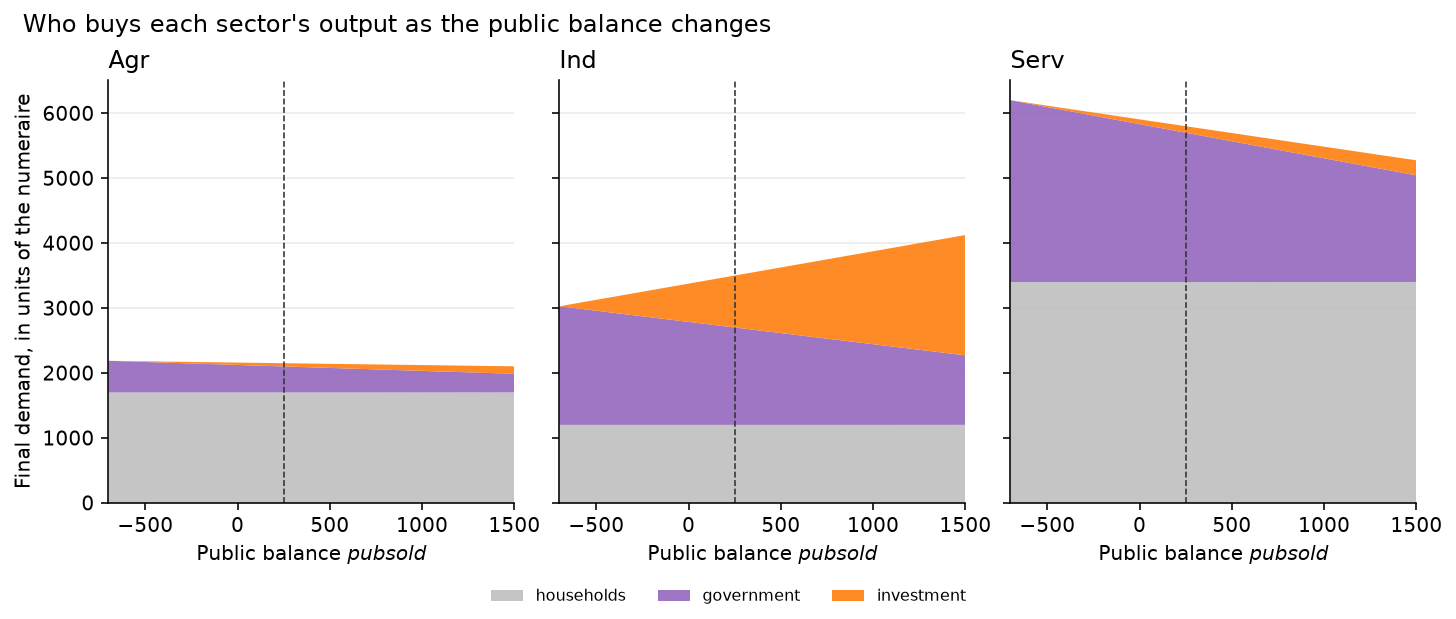

In [18]:
buyer_colors = {"households": "0.75", "government": "C4", "investment": "C1"}

fig, axes = plt.subplots(ncols=len(sectors),
                         figsize=(10, 4.2),
                         dpi=144,
                         sharex=True,
                         sharey=True,
                         layout="constrained")
for ax, sector in zip(axes, sectors):
    ax.stackplot(balance_sweep["pubsold"],
                 *[spending.sel(i=sector) for spending in purchases.values()],
                 labels=list(purchases),
                 colors=list(buyer_colors.values()),
                 alpha=0.9,
                 linewidth=0)
    ax.axvline(benchmark_balance,
               color="0.2",
               linewidth=0.8,
               linestyle="--")
    ax.set_title(sector,
                 loc="left")
    ax.set_xlabel("Public balance $pubsold$")
    ax.grid(axis="y",
            color="0.92")
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)

axes[0].set_xlim(float(balance_sweep["pubsold"].min()), float(balance_sweep["pubsold"].max()))
axes[0].set_ylabel("Final demand, in units of the numeraire")
fig.suptitle("Who buys each sector's output as the public balance changes",
             x=0.01,
             ha="left")

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles=handles,
           labels=labels,
           loc="outside lower center",
           ncol=len(labels),
           frameon=False,
           fontsize=8)
plt.show()

Household purchases hardly move, because the public balance changes neither household income nor the saving rate. Each extra unit of public surplus takes one unit from the government's budget and adds one unit to investment, so government spending plus investment stays close to 5150 and only its split between the two buyers changes. The two buyers want different goods. Investment goes 84% to industry, while the government spends 55% of its budget on services and 10% on agriculture. A larger surplus therefore moves production from services, and a little from agriculture, to industry. The table below gives the change in sector output at the two ends of the sweep.

In [19]:
sweep_ends = balance_sweep.isel(step=[0, -1])
output_change = 100 * (sweep_ends["Y"] / calibrated_values["Y"] - 1)
pd.DataFrame(output_change.values,
             index=[f"pubsold = {balance:.0f}" for balance in sweep_ends["pubsold"].values],
             columns=sectors).rename_axis("Y growth (%)").round(2)

,Agr,Ind,Serv
Y growth (%),,,
pubsold = -700,0.72,-4.05,3.33
pubsold = 1500,-0.95,5.25,-4.40


Moving from a deficit of 700 to a surplus of 1500 raises industrial output by about 9.7% and cuts services output by about 7.5%, with the same factor supplies and the same household behavior. In this closure the government's choice of public balance decides how much of the economy's saving becomes investment, and through the composition of investment it also decides what the economy produces.

The economy is closed, so household saving and the public balance are the only sources of finance for investment. The next lecture adds the rest of the world, which can lend to the economy or borrow from it.

## Authors

- Created by Jesse Grabowski, November 26, 2026

## Watermark

In [20]:
%load_ext watermark
%watermark -n -u -v -iv -m -w

Last updated: Thu, 26 Nov 2026

Python implementation: CPython
Python version       : 3.12.13
IPython version      : 9.18.1

Compiler    : Clang 19.1.7 
OS          : Darwin
Release     : 25.6.0
Machine     : arm64
Processor   : arm
CPU cores   : 14
Architecture: 64bit

cge_modeling: 0.0.7.dev15+g93cb61e4e.d20261120
matplotlib  : 3.11.2
numpy       : 2.3.5
pandas      : 3.1.1
xarray      : 2026.9.0

Watermark: 2.6.0

